# Prévision des prix des produits alimentaires au Maroc — XGBoost

**Sujet 26** : prévoir les prix (tomate, pomme de terre, oignon, agrumes, viandes…) selon la saison et l'offre.

**Données** : prix de gros **hebdomadaires** en DH/kg du marché de gros de Casablanca, 2024-2026, 19 produits.
**Modèle** : XGBoost global, stratégie multi-horizon directe (1 à 8 semaines).

**Protocole** : backtest à origines glissantes — à chaque date d'origine, le modèle est ré-entraîné avec les seules données connues à cette date, puis ses prévisions sont comparées aux prix réels.

Les calculs sont faits par `run_all.py` (environ 1 minute) ; ce notebook lit les résultats dans `resultats/`. Pour tout recalculer, mettre `RECALCULER = True`.

In [1]:
import subprocess, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.precision", 2)
R = Path("resultats")
RECALCULER = False
if RECALCULER:
    subprocess.run([sys.executable, "run_all.py"], check=True)

## 1. Les données

- **Prix hebdomadaires** : bulletins hebdomadaires de Casablanca Prestations (marché de gros des fruits et légumes et abattoirs), collectés dans la presse marocaine en français et en arabe (31 sites), contrôlés (écart médian de 0 % entre les deux langues sur les fourchettes min-max). Prix moyen = (min + max) / 2.
- **Variables exogènes** : météo hebdomadaire (Open-Meteo/ERA5) du Souss (principal bassin de production) et de Casablanca, calendrier (Ramadan, Aïd al-Adha).
- Les semaines sans bulletin dans la presse sont interpolées pour calculer les variables, mais **seules les semaines réellement relevées servent de cible** d'apprentissage et d'évaluation.

19 produits, 147 semaines (2024-01-17 -> 2026-11-04), 1053 prix relevés


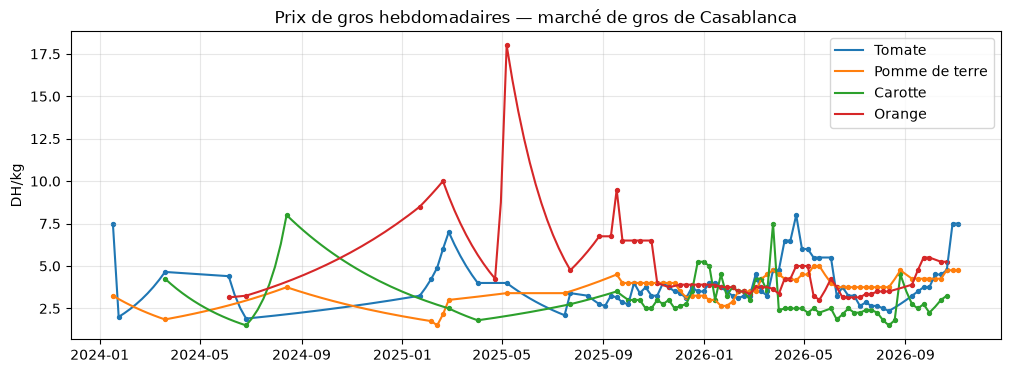

produit,Tomate,Pomme de terre,Carotte,Concombre,Chou blanc,Orange,Aubergine,Oignon frais,Courgette,Chou-fleur,Avocat,Pomme locale,Viande bovine,Viande ovine,Banane locale,Pomme importée,Courge,Banane importée,Clémentine
semaines relevées,74,66,60,60,58,58,57,57,57,56,55,55,54,53,53,51,49,45,35


In [2]:
sys.path.insert(0, ".")
from donnees import series_hebdo
w, observe, exo = series_hebdo()
print(f"{w.shape[1]} produits, {len(w)} semaines ({w.index[0]:%Y-%m-%d} -> {w.index[-1]:%Y-%m-%d}), "
      f"{int(observe.values.sum())} prix relevés")
fig, ax = plt.subplots(figsize=(12, 4))
for p in ["Tomate", "Pomme de terre", "Carotte", "Orange"]:
    ax.plot(w.index, w[p], label=p)
    ax.scatter(w.index[observe[p]], w[p][observe[p]], s=8)
ax.set(title="Prix de gros hebdomadaires — marché de gros de Casablanca", ylabel="DH/kg"); ax.legend(); ax.grid(alpha=.3)
plt.show()
display(observe.sum().sort_values(ascending=False).rename("semaines relevées").to_frame().T)

## 2. Le modèle XGBoost

**Formulation** : stratégie *directe* — un modèle par horizon h = 1…8 semaines, global (tous les produits ensemble). La cible est la variation du log-prix `log p(t+h) − log p(t)`, ce qui rend les produits comparables (quelques DH/kg pour la tomate, plus de 100 DH/kg pour la viande). La prévision est `p(t) × exp(ŷ)`.

**Variables** (toutes connues à la date t) :

| Groupe | Variables |
|---|---|
| Dynamique du prix | variations sur 1, 4 et 13 semaines ; écart à la moyenne et volatilité sur 8 semaines |
| Saisonnalité | effet saisonnier attendu (profil harmonique estimé sur l'historique) ; évolution l'an passé à la même période ; semaine et mois cibles |
| Demande | Ramadan, semaine avant Ramadan, Aïd al-Adha, semaine avant l'Aïd (dans la semaine cible) |
| Offre | pluie et températures du Souss sur 4 semaines ; pluie à Casablanca |
| Produit | produit et famille (légume, fruit, viande), en variables catégorielles |

**Réglage** : 4 configurations testées, choix sur la première moitié des origines (validation) → arbres de profondeur 2, 400 arbres, taux d'apprentissage 0,01, forte régularisation (λ = 30, poids minimal des feuilles = 30). Perte de Huber (robuste aux pics de prix).

**Sans fuite de données** : à chaque origine, la série est reconstruite avec les seuls relevés connus, et la prévision part du dernier prix réellement relevé.

## 3. Résultats

Métriques par horizon :
- **MAPE** : erreur absolue moyenne en % ;
- **erreur médiane** : la moitié des prévisions font mieux ;
- **RMSE (log)** : racine de l'erreur quadratique moyenne sur le log-prix ;
- **à ±10 %** : part des prévisions à moins de 10 % du prix réel ;
- **sens correct** : part des cas où XGBoost prévoit le bon sens de variation (hausse/baisse), quand le prix réel bouge d'au moins 2 %.

,MAPE_pct,erreur_mediane_pct,RMSE_log,part_a_10pct,sens_correct_pct,n
horizon,,,,,,
1,12.92,2.65,0.25,75.65,51.90,345
2,13.37,5.10,0.23,65.59,54.90,340
3,21.17,8.40,0.29,55.72,47.70,332
4,19.60,9.88,0.28,50.31,54.44,326
5,22.44,11.19,0.31,44.93,54.79,345
6,21.96,12.49,0.30,43.63,54.32,314
7,25.60,13.90,0.33,41.28,54.20,327
8,26.92,16.99,0.35,33.44,53.09,302


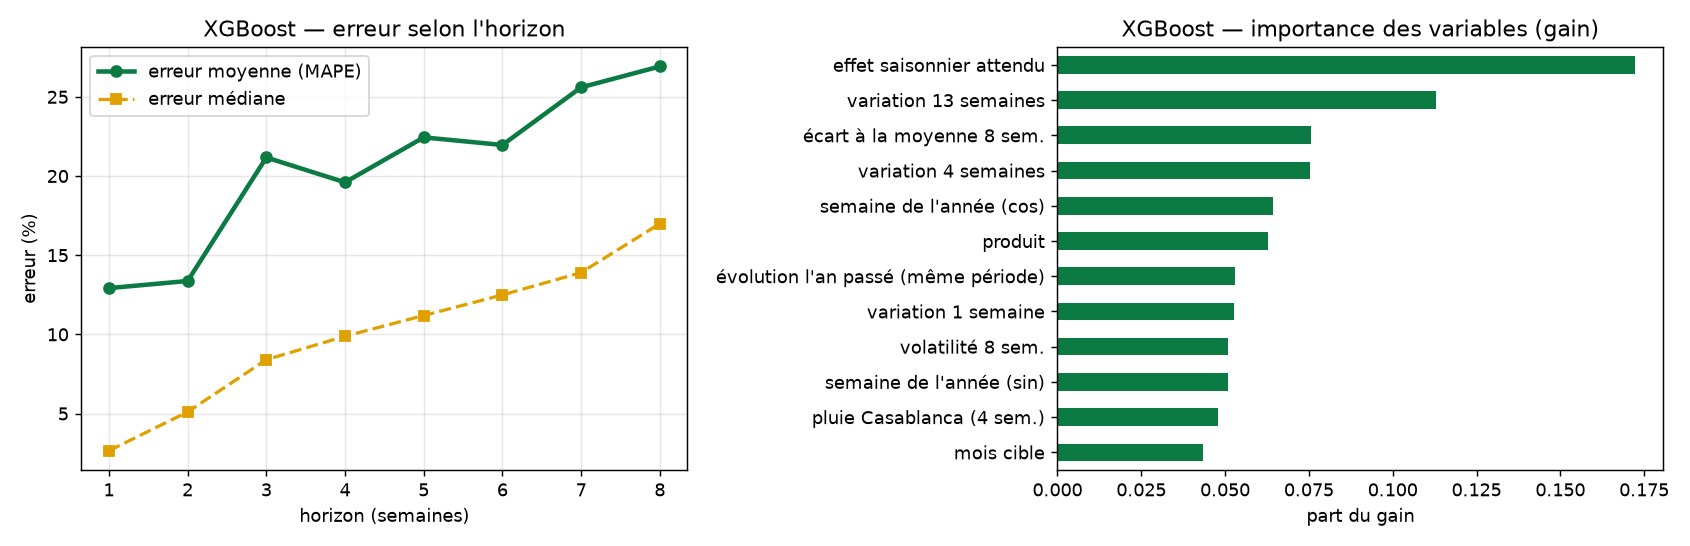

In [3]:
display(pd.read_csv(R / "xgb_hebdo_erreur_horizon.csv", index_col=0))
display(Image(R / "fig1_xgb_hebdo.png"))

In [4]:
print("Erreur par produit (tous horizons) :")
display(pd.read_csv(R / "xgb_hebdo_erreur_produit.csv", index_col=0))

Erreur par produit (tous horizons) :


,MAPE_pct,erreur_mediane_pct,n
produit,,,
Pomme importée,2.5,1.9,142
Viande ovine,5.3,3.7,130
Banane locale,9.2,8.3,137
Courge,9.6,5.0,135
Avocat,11.6,8.7,122
Chou-fleur,11.8,6.9,145
Orange,11.9,7.5,144
Pomme de terre,13.0,9.9,161
Pomme locale,13.0,5.7,151


**Lecture des résultats**

- À **1 semaine**, l'erreur médiane n'est que de **2,7 %** et **3 prévisions sur 4** sont à moins de 10 % du prix réel. L'erreur moyenne (12,9 %) est plus élevée car quelques **chocs de prix** (vagues de chaleur, maladies, arrêts des exportations) produisent de grosses erreurs.
- La précision **diminue avec l'horizon** : erreur médiane de 17 % et un tiers des prévisions à ±10 % à 8 semaines.
- Le **sens de variation** est correct dans un peu plus de la moitié des cas (≈ 52-55 %) : prévoir la direction des prix de gros reste difficile à court terme.
- Les produits les plus prévisibles sont les produits importés ou stockables (pomme importée, viande ovine, banane) ; les plus difficiles sont les légumes frais (tomate, courgette, concombre, clémentine).
- L'**importance des variables** est conforme à l'intuition économique : l'effet saisonnier attendu, l'écart à la moyenne récente (retour à la moyenne), le Ramadan et la météo du Souss sont les facteurs les plus utilisés.

In [5]:
prev = pd.read_csv(R / "xgb_hebdo_prevision_8_semaines.csv")
print("Prévision XGBoost des 8 prochaines semaines (DH/kg) :")
display(prev.pivot_table(index="produit", columns="semaine", values="prevision_XGBoost_DH_kg"))

Prévision XGBoost des 8 prochaines semaines (DH/kg) :


semaine,2026-10-28,2026-11-04,2026-11-11,2026-11-18,2026-11-25,2026-12-02,2026-12-09,2026-12-16,2026-12-23,2026-12-30
produit,,,,,,,,,,
Aubergine,NaN,4.39,4.35,4.13,4.02,4.04,4.14,4.09,4.06,NaN
Avocat,NaN,18.12,18.08,18.26,18.20,17.64,17.54,17.54,17.89,NaN
Banane importée,NaN,11.47,11.29,11.44,11.46,11.37,11.13,11.44,11.30,NaN
Banane locale,9.98,9.78,9.81,9.61,8.99,9.05,8.88,8.83,NaN,NaN
Carotte,3.15,3.07,3.06,3.16,3.21,3.24,3.23,3.21,NaN,NaN
Chou blanc,NaN,2.20,2.11,2.05,1.97,1.97,1.97,1.91,1.85,NaN
Chou-fleur,NaN,2.24,2.17,2.06,1.98,1.89,1.84,1.80,1.71,NaN
Clémentine,NaN,5.05,4.96,4.87,4.76,4.62,4.65,4.63,4.63,NaN
Concombre,NaN,4.38,4.10,3.85,3.78,3.72,3.74,3.85,4.08,NaN


## 4. Conclusions

1. **XGBoost** prévoit les prix de gros hebdomadaires de Casablanca avec une erreur médiane de 2,7 % à 1 semaine et 17 % à 8 semaines ; l'erreur moyenne (13 % à 27 %) est dominée par quelques chocs de prix imprévisibles.
2. Le modèle **identifie les facteurs** des prix : saison, retour à la moyenne, Ramadan, météo du Souss.
3. **Limites** : un seul marché (Casablanca) ; semaines manquantes dans la presse (81 semaines relevées sur 147) ; environ 2,5 ans d'historique, ce qui limite l'apprentissage — quelques années de bulletins supplémentaires permettraient à XGBoost d'exploiter davantage les variables d'offre ; prix de gros et non de détail.